In [ ]:
# Article title: Identification of Thermal Class-Specific Genomic and Proteomic Compositional Signatures in Bacteria Using a Weighted Ensemble Feature Ranking Framework, 
# Author Names: Biraj Khound1, Deb K Boruah1, Pranjal Phukan1, Kalyan Sarma1, Prince Das1, Robita Doley2, Alicia Passah1;
# Affiliation: 
# 1 Department of Diagnostic and Interventional Radiology, All India Institute of Medical Sciences, Changsari, Guwahati, 781101, Assam, India.
# 2 Department of Molecular Biology and Biotechnology, Tezpur University, Napaam, Tezpur, 784028, Assam, India.
# E-mail address of the corresponding author: prsbirajaiimsguwahati@gmail.com

In [290]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # for data visualization
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
# import RFC classifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
# Scaller
from sklearn.preprocessing import MinMaxScaler
# compute ROC AUC
from sklearn.metrics import roc_auc_score, roc_curve, auc
pd.set_option('display.max_colwidth', None)  # None means no limit
# feature selectors
%matplotlib inline

In [291]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [292]:
dub = "/content/drive/MyDrive/paper-1/Dataset/DUB.csv"
cub = "/content/drive/MyDrive/paper-1/Dataset/CUB.csv"
cpub = "/content/drive/MyDrive/paper-1/Dataset/CPUB.csv"
aaub = "/content/drive/MyDrive/paper-1/Dataset/AAUB.csv"
aapub = "/content/drive/MyDrive/paper-1/Dataset/AAPUB.csv"
df = pd.read_csv(aapub, encoding="ISO-8859-1", na_filter=False)

In [293]:
# codon usage Bias
x_psyc = df.loc[0:17,].drop(['label-1', 'label-2'], axis=1)
x_meso = df.loc[18:52,].drop(['label-1', 'label-2'], axis=1)
x_ther = df.loc[53:84,].drop(['label-1', 'label-2'], axis=1)
# psychro vs meso and psy vs thermo
y_psyc = df.loc[0:17, ['label-1']]
y_meso = df.loc[18:52, ['label-1']]
y_ther = df.loc[53:84, ['label-1']]
# psy vs meso
y_psyc2 = df.loc[0:17, ['label-2']]
y_meso2 = df.loc[18:52, ['label-2']]
# combine data and label
x_ps_vs_me = pd.concat([x_psyc, x_meso], ignore_index=True)
y_ps_vs_me = pd.concat([y_psyc2, y_meso2], ignore_index=True)
#-------
x_me_vs_th = pd.concat([x_meso, x_ther], ignore_index=True)
y_me_vs_th = pd.concat([y_meso, y_ther], ignore_index=True)
#-------
x_th_vs_ps = pd.concat([x_psyc, x_ther], ignore_index=True)
y_th_vs_ps = pd.concat([y_psyc, y_ther], ignore_index=True)


In [294]:
roc_auc_plot_tittle = 'Amino Acid Pair Usage Bias (Permuted Labels) ( Psychrophiles vs Mesophiles )'
# Permuted Labels
y = pd.DataFrame(np.random.permutation(y_ps_vs_me)).values.ravel()
# Correct labels
# y = y_th_vs_ps.values.ravel()
# ____________.values.flatten()
x = x_ps_vs_me
# Data Normalization
# Initialize scaler
min_max_scaler = MinMaxScaler()
# Fit and transform data
x_scaled = min_max_scaler.fit_transform(x)
# Convert back to DataFrame for readability
x_scaled = pd.DataFrame(x_scaled, columns=x.columns)

In [295]:
# Define model
classifiers = [ RandomForestClassifier(),SVC(probability=True), GaussianNB(), AdaBoostClassifier(),LogisticRegression(), KNeighborsClassifier(), XGBClassifier()]

# Define 5-fold Stratified Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True,random_state=42)

In [296]:
X = x_scaled
Y = y

result = []
# Evaluate using cross-validation
for c in range(0,len(classifiers)):
   ac_scores = cross_val_score(classifiers[c], X, Y, cv=skf, scoring='accuracy')
   accuracy = f"{np.mean(ac_scores):.4f} \u00B1 {np.std(ac_scores):.4f}"
   f1_scores = cross_val_score(classifiers[c], X, Y, cv=skf, scoring='f1')
   f1_score = f"{np.mean(f1_scores):.4f} \u00B1 {np.std(f1_scores):.4f}"
   pr_scores = cross_val_score(classifiers[c], X, Y, cv=skf, scoring='precision')
   precision = f"{np.mean(pr_scores):.4f} \u00B1 {np.std(pr_scores):.4f}"
   re_scores = cross_val_score(classifiers[c], X, Y, cv=skf, scoring='recall')
   recall = f"{np.mean(re_scores):.4f} \u00B1 {np.std(re_scores):.4f}"
   roc_auc_scores = cross_val_score(classifiers[c], X, Y, cv=skf, scoring='roc_auc')
   roc_auc = f"{np.mean(roc_auc_scores):.4f} \u00B1 {np.std(roc_auc_scores):.4f}"
   jw_scores = cross_val_score(classifiers[c], X, Y, cv=skf, scoring='jaccard_weighted')
   j_weight = f"{np.mean(jw_scores):.4f} \u00B1 {np.std(jw_scores):.4f}"
   mc_scores = cross_val_score(classifiers[c], X, Y, cv=skf, scoring='matthews_corrcoef')
   mc_coef = f"{np.mean(mc_scores):.4f} \u00B1 {np.std(mc_scores):.4f}"
   result.append({ 'classifiers': classifiers[c].__class__.__name__, 'accuracy': accuracy,  'precision': precision, 'recall' : recall,'f1 score': f1_score,
                  'roc_auc_score': roc_auc,'jaccard_weighted': j_weight,'matthews_corrcoef': mc_coef})
result = pd.DataFrame(result)
result.to_csv('/content/drive/MyDrive/paper-1/Classification_result/'+roc_auc_plot_tittle+'_classification_outputs.xlsx', index=True)

In [297]:
result

,classifiers,accuracy,precision,recall,f1 score,roc_auc_score,jaccard_weighted,matthews_corrcoef
0,RandomForestClassifier,0.6073 ± 0.0951,0.6367 ± 0.0833,0.7714 ± 0.1143,0.7533 ± 0.0731,0.5000 ± 0.0828,0.4093 ± 0.0526,-0.1709 ± 0.0756
1,SVC,0.6255 ± 0.0901,0.6488 ± 0.0480,0.9143 ± 0.1714,0.7548 ± 0.0939,0.5214 ± 0.0833,0.4193 ± 0.0680,-0.0357 ± 0.0714
2,GaussianNB,0.4164 ± 0.1042,0.5444 ± 0.0648,0.5429 ± 0.2286,0.5271 ± 0.1502,0.4702 ± 0.1316,0.2712 ± 0.0807,-0.3216 ± 0.0944
3,AdaBoostClassifier,0.6600 ± 0.0466,0.7352 ± 0.0494,0.7714 ± 0.1143,0.7471 ± 0.0437,0.5667 ± 0.1023,0.4936 ± 0.0450,0.1849 ± 0.1577
4,LogisticRegression,0.5473 ± 0.0657,0.6450 ± 0.0277,0.6857 ± 0.1666,0.6564 ± 0.0936,0.5071 ± 0.1371,0.3835 ± 0.0517,-0.0563 ± 0.1130
5,KNeighborsClassifier,0.6636 ± 0.1019,0.6939 ± 0.0502,0.8571 ± 0.1807,0.7608 ± 0.1009,0.5631 ± 0.1962,0.4873 ± 0.0990,0.1916 ± 0.2267
6,XGBClassifier,0.6055 ± 0.0585,0.6840 ± 0.0343,0.7429 ± 0.1400,0.7068 ± 0.0689,0.6310 ± 0.0714,0.4358 ± 0.0454,0.0585 ± 0.0864


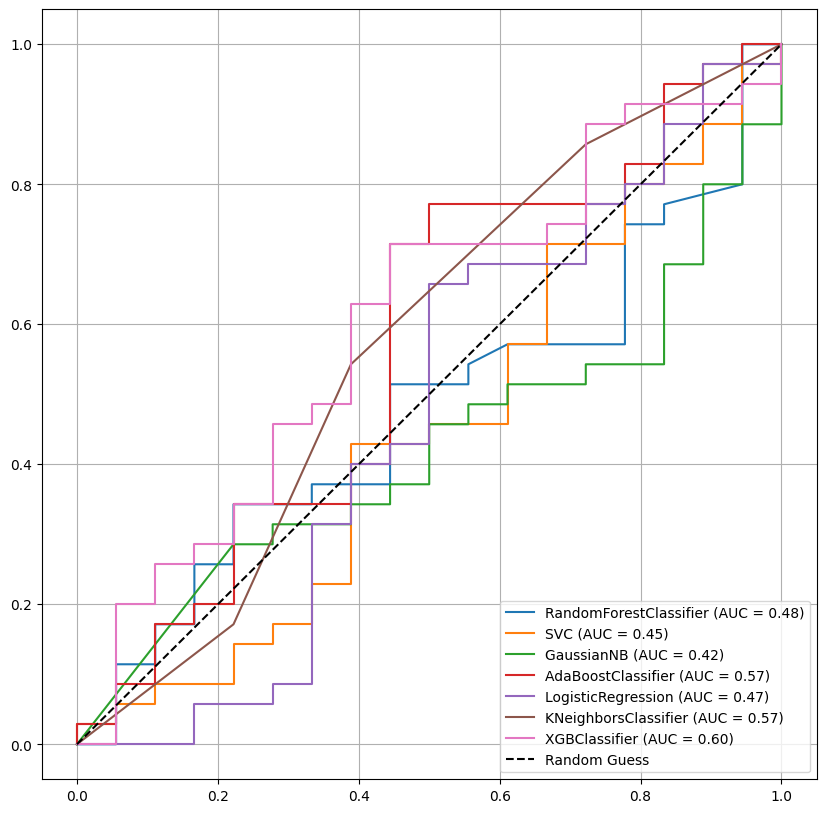

In [ ]:

# Create a bar plot
plt.figure(figsize=(10, 10))
for c in range(0,len(classifiers)):
   # Get cross-validated predicted probabilities
   y_prob = cross_val_predict(classifiers[c], X, Y, cv=skf, method='predict_proba')
   # Compute ROC
   fpr, tpr, thresholds = roc_curve(Y, y_prob[:,1])
   roc_auc = auc(fpr, tpr)
   # plot
   plt.plot(fpr, tpr, label=f'{str(classifiers[c]).rsplit("(", 1)[0].strip()} (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
# Update global font properties
plt.rcParams.update({
    'font.size': 14.5,           # Base font size
    'font.family': 'serif',      # Options: 'sans-serif', 'serif', 'monospace'
    'axes.titlesize': 14.5,      # Title font size
    'axes.labelsize': 14.5,      # X and Y label font size
    'xtick.labelsize': 14.5,     # X-axis tick font size
    'ytick.labelsize': 14.5,     # Y-axis tick font size
    'legend.fontsize': 17        # Legend font size
})
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
# plt.title('ROC_AUC Curve Comparison for '+roc_auc_plot_tittle)
plt.legend(loc='lower right')
# plt.legend(loc='upper left')
plt.grid(True)
plt.savefig("/content/drive/MyDrive/paper-1/Classification_result/ROC_AUC Curve Comparison for "+roc_auc_plot_tittle+".tiff", dpi=300, bbox_inches='tight')
plt.show()